# Retail Driver Analysis — Monthly Promotion and Sales Trends

## Business Objective

Investigate monthly sales trends and promotional activity
to identify patterns relevant to retail sales forecasting.

## Business Questions

1. How do total sales change over time?
2. How does promotion activity change over time?
3. Are higher-promotion months associated with higher sales?
4. Do promotional patterns vary by year or season?
5. Which findings could improve future sales forecasts?

## Analysis Period

January 2013 – July 2017 (55 complete months).

## Analytical Limitations

- Sales are aggregated at store–family–day level.
- `onpromotion` counts promoted items.
- Promotion record share is not discount penetration.
- Correlation does not establish causation.

In [1]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "data" / "processed").exists():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError("Project root not found.")
    PROJECT_ROOT = PROJECT_ROOT.parent

sales = pd.read_csv(
    PROJECT_ROOT / "data/processed/train_standardized.csv",
    usecols=["date", "store_nbr", "family", "sales", "onpromotion"],
    parse_dates=["date"]
)

sales = sales.loc[
    sales["date"].between("2013-01-01", "2017-07-31")
].copy()

sales["month"] = sales["date"].dt.to_period("M")
sales["has_promotion"] = sales["onpromotion"] > 0

print("Records:", len(sales))
print("Stores:", sales["store_nbr"].nunique())
print("Families:", sales["family"].nunique())
print("Months:", sales["month"].nunique())
print("Total sales:", round(sales["sales"].sum(), 2))

assert len(sales) == 2_974_158
assert sales["store_nbr"].nunique() == 54
assert sales["family"].nunique() == 33
assert sales["month"].nunique() == 55

print("Monthly analysis source validation passed.")

Records: 2974158
Stores: 54
Families: 33
Months: 55
Total sales: 1061211629.26
Monthly analysis source validation passed.


## 3. Monthly Sales and Promotion KPI Aggregation

Aggregate store–family–day records into monthly business-level metrics.

KPIs:
- Monthly total sales
- Total source records
- Records with promotional activity
- Total promoted-item counts
- Promotion record share (%)
- Average sales per source record

In [2]:
monthly_performance = (
    sales.groupby("month", as_index=False)
    .agg(
        monthly_sales=("sales", "sum"),
        total_records=("sales", "size"),
        promotional_records=("has_promotion", "sum"),
        total_promoted_item_counts=("onpromotion", "sum"),
    )
)

monthly_performance["promotion_record_share_pct"] = (
    monthly_performance["promotional_records"]
    / monthly_performance["total_records"]
    * 100
)

monthly_performance["avg_sales_per_record"] = (
    monthly_performance["monthly_sales"]
    / monthly_performance["total_records"]
)

monthly_performance["month"] = (
    monthly_performance["month"].dt.to_timestamp()
)

monthly_performance = monthly_performance.sort_values(
    "month"
).reset_index(drop=True)

display(monthly_performance.head(10).round(2))

C:\Users\Dell\AppData\Local\Temp\ipykernel_8888\988083043.py:30: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_performance.head(10).round(2))


,month,monthly_sales,total_records,promotional_records,total_promoted_item_counts,promotion_record_share_pct,avg_sales_per_record
0,2013-01-01,10327624.74,55242,0,0,0.0,186.95
1,2013-02-01,9658959.78,49896,0,0,0.0,193.58
2,2013-03-01,11428497.04,55242,0,0,0.0,206.88
3,2013-04-01,10993464.74,53460,0,0,0.0,205.64
4,2013-05-01,11597704.01,55242,0,0,0.0,209.94
5,2013-06-01,11689344.06,53460,0,0,0.0,218.66
6,2013-07-01,11257400.61,55242,0,0,0.0,203.78
7,2013-08-01,11737788.92,55242,0,0,0.0,212.48
8,2013-09-01,11792933.23,53460,0,0,0.0,220.59
9,2013-10-01,11775620.36,55242,0,0,0.0,213.16


In [3]:
assert len(monthly_performance) == 55

assert monthly_performance["month"].is_unique

assert (
    monthly_performance["total_records"].sum()
    == len(sales)
)

assert (
    monthly_performance["promotional_records"].sum()
    == sales["has_promotion"].sum()
)

assert (
    monthly_performance["total_promoted_item_counts"].sum()
    == sales["onpromotion"].sum()
)

assert abs(
    monthly_performance["monthly_sales"].sum()
    - sales["sales"].sum()
) < 0.01

assert monthly_performance[
    "promotion_record_share_pct"
].between(0, 100).all()

assert (
    monthly_performance["promotional_records"]
    <= monthly_performance["total_records"]
).all()

print("Monthly aggregation validation passed.")
print("Months:", len(monthly_performance))
print("Total records:", monthly_performance["total_records"].sum())
print("Total sales:", round(monthly_performance["monthly_sales"].sum(), 2))
print("Promotional records:", monthly_performance["promotional_records"].sum())

Monthly aggregation validation passed.
Months: 55
Total records: 2974158
Total sales: 1061211629.26
Promotional records: 599545


## 4. Monthly Sales Trend Analysis

### Business Question

How have monthly retail sales changed from January 2013
through July 2017?

### Analytical Approach

Visualize monthly total sales to investigate:

- Long-term growth or decline
- Seasonal fluctuations
- Unusually high or low sales months
- Potential implications for forecasting

All 55 complete months are retained.

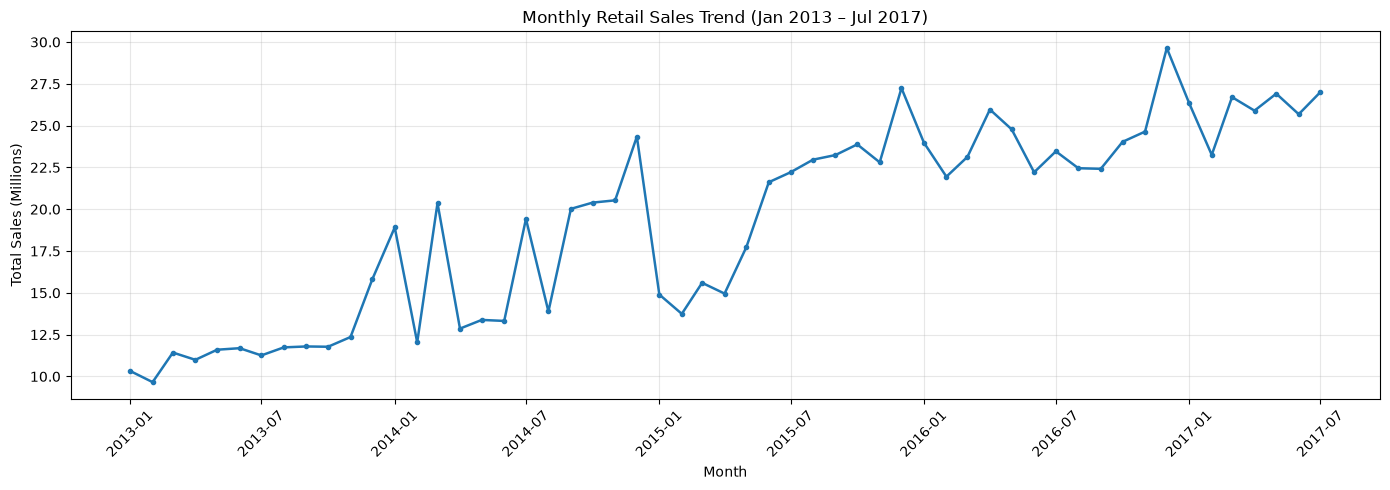

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_performance["month"],
    monthly_performance["monthly_sales"] / 1_000_000,
    marker="o",
    markersize=3,
    linewidth=1.8
)

plt.title("Monthly Retail Sales Trend (Jan 2013 – Jul 2017)")
plt.xlabel("Month")
plt.ylabel("Total Sales (Millions)")

plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [5]:
highest_month = monthly_performance.loc[
    monthly_performance["monthly_sales"].idxmax()
]

lowest_month = monthly_performance.loc[
    monthly_performance["monthly_sales"].idxmin()
]

print("Highest sales month:")
print("Month:", highest_month["month"].strftime("%Y-%m"))
print("Sales:", round(highest_month["monthly_sales"], 2))

print("\nLowest sales month:")
print("Month:", lowest_month["month"].strftime("%Y-%m"))
print("Sales:", round(lowest_month["monthly_sales"], 2))

print("\nAverage monthly sales:")
print(round(monthly_performance["monthly_sales"].mean(), 2))

Highest sales month:
Month: 2016-12
Sales: 29640287.58

Lowest sales month:
Month: 2013-02
Sales: 9658959.78

Average monthly sales:
19294756.9


## 5. Monthly Promotion Activity Trend

### Business Question

How has promotional activity changed from January 2013
through July 2017?

### Metrics

- Promotion record share (%)
- Total promoted-item counts

### Important Distinction

Promotion record share measures the percentage of
store–family–day records containing at least one promoted item.

Total promoted-item counts sums the `onpromotion` field.

Neither metric measures promotional discount percentage
or proves incremental sales uplift.

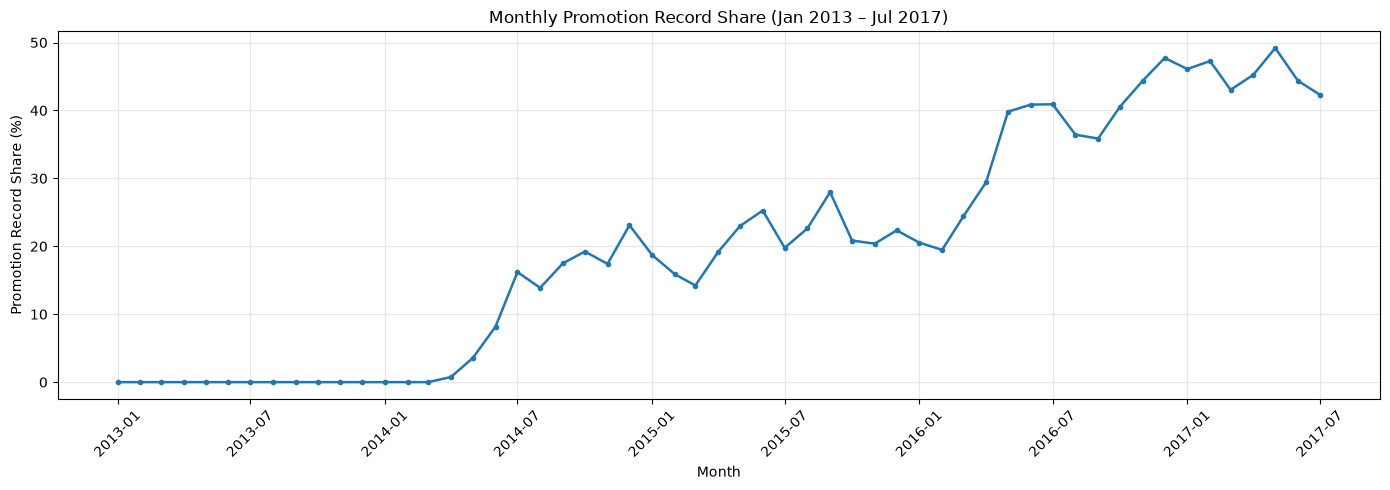

In [6]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    monthly_performance["month"],
    monthly_performance["promotion_record_share_pct"],
    marker="o",
    markersize=3,
    linewidth=1.8
)

ax.set_title(
    "Monthly Promotion Record Share (Jan 2013 – Jul 2017)"
)

ax.set_xlabel("Month")
ax.set_ylabel("Promotion Record Share (%)")

ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [7]:
highest_promo = monthly_performance.loc[
    monthly_performance["promotion_record_share_pct"].idxmax()
]

lowest_promo = monthly_performance.loc[
    monthly_performance["promotion_record_share_pct"].idxmin()
]

print("Highest promotion activity month:")
print("Month:", highest_promo["month"].strftime("%Y-%m"))
print(
    "Promotion share (%):",
    round(highest_promo["promotion_record_share_pct"], 2)
)

print("\nLowest promotion activity month:")
print("Month:", lowest_promo["month"].strftime("%Y-%m"))
print(
    "Promotion share (%):",
    round(lowest_promo["promotion_record_share_pct"], 2)
)

print("\nOverall promotion record share (%):")
print(
    round(
        monthly_performance["promotional_records"].sum()
        / monthly_performance["total_records"].sum()
        * 100,
        2
    )
)

Highest promotion activity month:
Month: 2017-05
Promotion share (%): 49.19

Lowest promotion activity month:
Month: 2013-01
Promotion share (%): 0.0

Overall promotion record share (%):
20.16


## 6. Monthly Sales vs. Promotion Activity

### Business Question

Do months with higher promotional activity also show higher sales?

### Analytical Approach

Compare monthly sales and promotion record share
using the same chronological timeline.

This is a descriptive comparison, not evidence
of promotional effectiveness or causality.

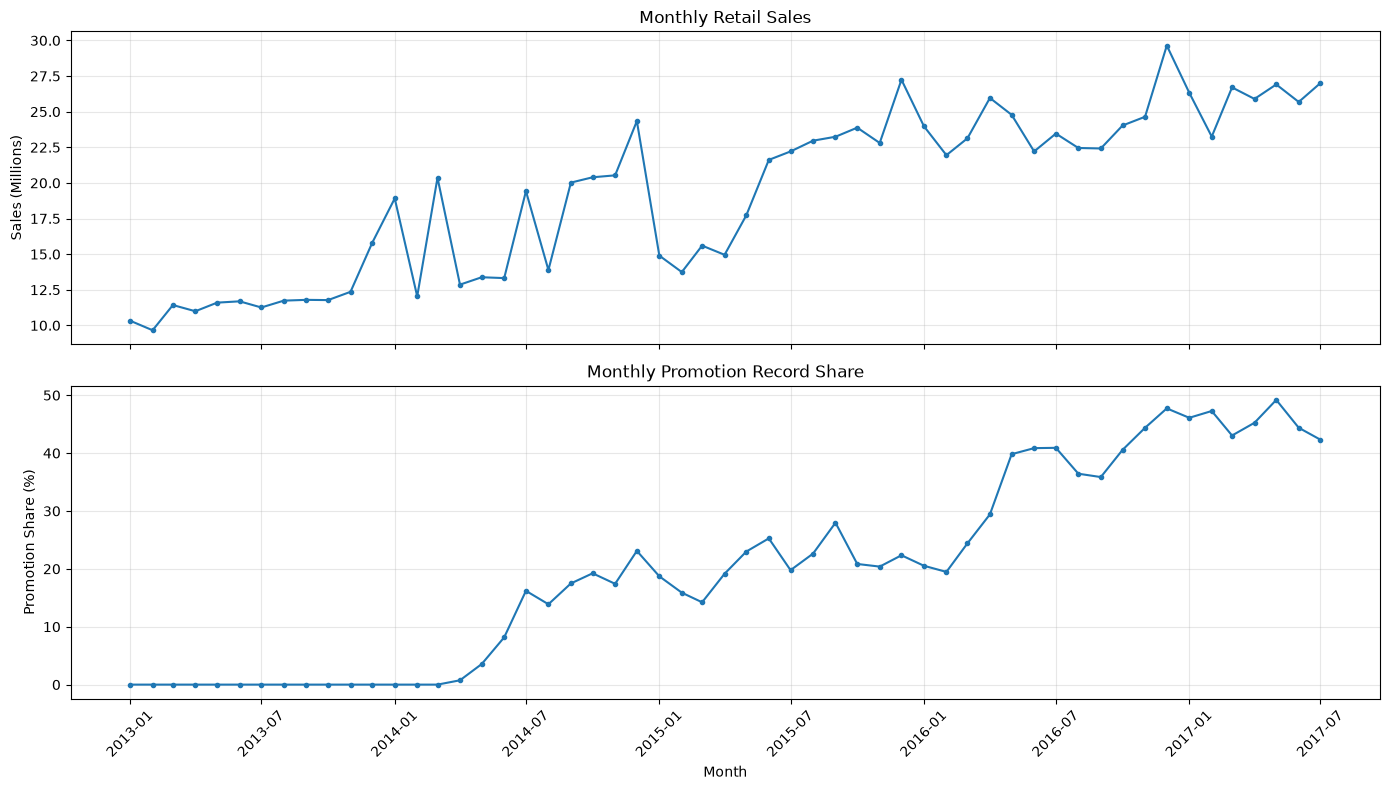

In [8]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 8),
    sharex=True
)

# Monthly sales
axes[0].plot(
    monthly_performance["month"],
    monthly_performance["monthly_sales"] / 1_000_000,
    marker="o",
    markersize=3
)

axes[0].set_title("Monthly Retail Sales")
axes[0].set_ylabel("Sales (Millions)")
axes[0].grid(alpha=0.3)

# Monthly promotion activity
axes[1].plot(
    monthly_performance["month"],
    monthly_performance["promotion_record_share_pct"],
    marker="o",
    markersize=3
)

axes[1].set_title("Monthly Promotion Record Share")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Promotion Share (%)")
axes[1].grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. Monthly Promotion–Sales Correlation

Pearson correlation measures the strength and direction
of a linear relationship between two numerical variables.

A positive correlation means the variables tend to move
in the same direction.

Correlation does not establish that promotions caused
sales to increase.

In [9]:
monthly_correlation = monthly_performance[
    "monthly_sales"
].corr(
    monthly_performance["promotion_record_share_pct"]
)

print(
    "Monthly Sales vs. Promotion Share Correlation:",
    round(monthly_correlation, 3)
)

assert -1 <= monthly_correlation <= 1

print("Correlation validation passed.")

Monthly Sales vs. Promotion Share Correlation: 0.866
Correlation validation passed.


## 8. Month-to-Month Changes and Correlation

### Business Objective

Investigate whether changes in promotional activity
are associated with changes in monthly sales.

### Method

Calculate:
1. Month-over-month sales growth (%).
2. Month-over-month promotion record share change
   (percentage points).
3. Pearson correlation between both changes.

### Limitation

First differences reduce some effects of long-term trends,
but do not eliminate seasonality, confounding, or
establish causality.

In [10]:
monthly_changes = monthly_performance[
    [
        "month",
        "monthly_sales",
        "promotion_record_share_pct"
    ]
].copy()

# Month-over-month sales growth (%)
monthly_changes["sales_mom_growth_pct"] = (
    monthly_changes["monthly_sales"].pct_change() * 100
)

# Month-over-month promotion share change
# Unit: percentage points, not percent growth
monthly_changes["promotion_change_pp"] = (
    monthly_changes["promotion_record_share_pct"].diff()
)

display(
    monthly_changes[
        [
            "month",
            "sales_mom_growth_pct",
            "promotion_change_pp"
        ]
    ].head(10).round(2)
)

C:\Users\Dell\AppData\Local\Temp\ipykernel_8888\3021741550.py:27: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).round(2)


,month,sales_mom_growth_pct,promotion_change_pp
0,2013-01-01,NaN,NaN
1,2013-02-01,-6.47,0.0
2,2013-03-01,18.32,0.0
3,2013-04-01,-3.81,0.0
4,2013-05-01,5.50,0.0
5,2013-06-01,0.79,0.0
6,2013-07-01,-3.70,0.0
7,2013-08-01,4.27,0.0
8,2013-09-01,0.47,0.0
9,2013-10-01,-0.15,0.0


In [11]:
valid_changes = monthly_changes.dropna(
    subset=[
        "sales_mom_growth_pct",
        "promotion_change_pp"
    ]
)

changes_correlation = valid_changes[
    "sales_mom_growth_pct"
].corr(
    valid_changes["promotion_change_pp"]
)

print("Original monthly correlation:", round(monthly_correlation, 3))
print("Month-to-month changes correlation:", round(changes_correlation, 3))
print("Valid month-to-month observations:", len(valid_changes))

assert len(valid_changes) == 54
assert valid_changes["month"].is_unique
assert -1 <= changes_correlation <= 1

print("Month-to-month correlation validation passed.")

Original monthly correlation: 0.866
Month-to-month changes correlation: 0.293
Valid month-to-month observations: 54
Month-to-month correlation validation passed.


## 9. Calendar-Month Seasonality Analysis

### Business Objective

Investigate whether sales and promotional activity
show recurring patterns across calendar months.

### Method

Group monthly observations by calendar month
(January through December).

Calculate:
- Average monthly sales
- Average promotion record share
- Number of observed years/months

### Limitations

The dataset contains 55 complete months.
January–July have five observations each.
August–December have four observations each.

Calendar-month averages are descriptive and may
be influenced by year-to-year growth or decline.

In [12]:
seasonality = monthly_performance.copy()

seasonality["month_number"] = seasonality["month"].dt.month
seasonality["month_name"] = seasonality["month"].dt.strftime("%B")

monthly_seasonality = (
    seasonality.groupby(
        ["month_number", "month_name"],
        as_index=False
    )
    .agg(
        avg_monthly_sales=("monthly_sales", "mean"),
        avg_promotion_share_pct=(
            "promotion_record_share_pct", "mean"
        ),
        observations=("monthly_sales", "size"),
    )
    .sort_values("month_number")
    .reset_index(drop=True)
)

display(monthly_seasonality.round(2))

,month_number,month_name,avg_monthly_sales,avg_promotion_share_pct,observations
0,1,January,18888430.46,17.07,5
1,2,February,16127445.89,16.53,5
2,3,March,19445697.43,16.33,5
3,4,April,18133623.51,18.91,5
4,5,May,18879827.40,23.11,5
5,6,June,18903340.66,23.73,5
6,7,July,20672612.14,23.84,5
7,8,August,17759763.47,18.24,4
8,9,September,19368419.98,20.33,4
9,10,October,20020094.79,20.16,4


In [13]:
assert len(monthly_seasonality) == 12

assert monthly_seasonality["observations"].sum() == 55

assert (
    monthly_seasonality.loc[
        monthly_seasonality["month_number"] <= 7,
        "observations"
    ] == 5
).all()

assert (
    monthly_seasonality.loc[
        monthly_seasonality["month_number"] >= 8,
        "observations"
    ] == 4
).all()

assert monthly_seasonality[
    "avg_promotion_share_pct"
].between(0, 100).all()

print("Calendar-month seasonality validation passed.")
print("Calendar months:", len(monthly_seasonality))
print("Total monthly observations:", monthly_seasonality["observations"].sum())

Calendar-month seasonality validation passed.
Calendar months: 12
Total monthly observations: 55


## 10. Within-Year Sales Seasonality Index

### Business Objective

Investigate calendar-month seasonality while reducing
the influence of differences in sales levels between years.

### Method

For each year:
1. Calculate average monthly sales.
2. Divide each month's sales by its year's average.
3. Compare calendar-month seasonal indices.

### Interpretation

- Index = 1.00: equal to that year's monthly average
- Index > 1.00: above that year's monthly average
- Index < 1.00: below that year's monthly average

### Limitation

2017 contains only January–July. Its annual average
is therefore based on seven observed months, not a
complete year.

For the primary seasonal comparison, use complete
calendar years 2013–2016.

In [14]:
seasonal_index_data = monthly_performance.copy()

seasonal_index_data["year"] = (
    seasonal_index_data["month"].dt.year
)

seasonal_index_data["month_number"] = (
    seasonal_index_data["month"].dt.month
)

# Use complete calendar years only
seasonal_index_data = seasonal_index_data.loc[
    seasonal_index_data["year"].between(2013, 2016)
].copy()

# Average monthly sales within each year
seasonal_index_data["year_avg_monthly_sales"] = (
    seasonal_index_data.groupby("year")["monthly_sales"]
    .transform("mean")
)

# Index relative to each year's average
seasonal_index_data["sales_seasonal_index"] = (
    seasonal_index_data["monthly_sales"]
    / seasonal_index_data["year_avg_monthly_sales"]
)

# Average seasonal index for each calendar month
seasonal_index_summary = (
    seasonal_index_data.groupby(
        "month_number",
        as_index=False
    )
    .agg(
        avg_seasonal_index=("sales_seasonal_index", "mean"),
        observations=("sales_seasonal_index", "size"),
    )
)

seasonal_index_summary["month_name"] = (
    pd.to_datetime(
        seasonal_index_summary["month_number"],
        format="%m"
    ).dt.strftime("%B")
)

display(
    seasonal_index_summary[
        [
            "month_number",
            "month_name",
            "avg_seasonal_index",
            "observations"
        ]
    ].round(3)
)

,month_number,month_name,avg_seasonal_index,observations
0,1,January,0.926,4
1,2,February,0.778,4
2,3,March,0.971,4
3,4,April,0.875,4
4,5,May,0.918,4
5,6,June,0.941,4
6,7,July,1.039,4
7,8,August,0.969,4
8,9,September,1.061,4
9,10,October,1.091,4


In [15]:
assert len(seasonal_index_data) == 48

assert seasonal_index_data["year"].nunique() == 4

assert (
    seasonal_index_data.groupby("year").size() == 12
).all()

assert len(seasonal_index_summary) == 12

assert (
    seasonal_index_summary["observations"] == 4
).all()

assert (
    seasonal_index_summary["avg_seasonal_index"] > 0
).all()

assert abs(
    seasonal_index_summary["avg_seasonal_index"].mean() - 1
) < 1e-10

print("Within-year seasonality validation passed.")
print("Complete years analyzed: 2013–2016")
print("Monthly observations:", len(seasonal_index_data))

december_index = seasonal_index_summary.loc[
    seasonal_index_summary["month_number"] == 12,
    "avg_seasonal_index"
].iloc[0]

print("December seasonal index:", round(december_index, 3))

Within-year seasonality validation passed.
Complete years analyzed: 2013–2016
Monthly observations: 48
December seasonal index: 1.334


## 11. December Seasonality Consistency

### Business Question

Does December consistently generate above-average
monthly sales across complete calendar years?

### Method

Compare December's sales seasonal index separately
for 2013, 2014, 2015, and 2016.

### Business Relevance

Consistent seasonal patterns can support forecasting,
inventory planning, staffing, and promotional calendars.

However, historical seasonality does not guarantee
future demand.

In [16]:
december_consistency = seasonal_index_data.loc[
    seasonal_index_data["month_number"] == 12,
    [
        "year",
        "monthly_sales",
        "year_avg_monthly_sales",
        "sales_seasonal_index"
    ]
].copy()

december_consistency["above_year_average"] = (
    december_consistency["sales_seasonal_index"] > 1
)

display(december_consistency.round(3))

,year,monthly_sales,year_avg_monthly_sales,sales_seasonal_index,above_year_average
11,2013,1.580312e+07,1.170158e+07,1.351,True
23,2014,2.434045e+07,1.745619e+07,1.394,True
35,2015,2.724398e+07,2.007334e+07,1.357,True
47,2016,2.964029e+07,2.405454e+07,1.232,True


In [17]:
assert len(december_consistency) == 4

assert december_consistency["year"].is_unique

assert set(december_consistency["year"]) == {
    2013, 2014, 2015, 2016
}

assert (
    december_consistency["sales_seasonal_index"] > 0
).all()

years_above_average = (
    december_consistency["above_year_average"].sum()
)

print("December consistency validation passed.")
print("Years analyzed:", len(december_consistency))
print("Years December exceeded annual monthly average:",
      years_above_average)

print(
    "Minimum December index:",
    round(december_consistency["sales_seasonal_index"].min(), 3)
)

print(
    "Maximum December index:",
    round(december_consistency["sales_seasonal_index"].max(), 3)
)

December consistency validation passed.
Years analyzed: 4
Years December exceeded annual monthly average: 4
Minimum December index: 1.232
Maximum December index: 1.394


## 12. Calendar-Day Adjusted Sales Seasonality

### Business Question

Is February's lower monthly sales performance
partly explained by having fewer calendar days?

### Method

1. Calculate the number of calendar days in each month.
2. Divide monthly sales by calendar days.
3. Compare average daily sales across calendar months.

### Limitations

Sales per calendar day adjusts for month length,
but not for store openings, holidays, weekday mix,
or long-term sales growth.

In [18]:
daily_adjusted = monthly_performance.copy()

daily_adjusted["calendar_days"] = (
    daily_adjusted["month"].dt.days_in_month
)

daily_adjusted["sales_per_calendar_day"] = (
    daily_adjusted["monthly_sales"]
    / daily_adjusted["calendar_days"]
)

daily_adjusted["month_number"] = (
    daily_adjusted["month"].dt.month
)

daily_adjusted["month_name"] = (
    daily_adjusted["month"].dt.strftime("%B")
)

daily_seasonality = (
    daily_adjusted.groupby(
        ["month_number", "month_name"],
        as_index=False
    )
    .agg(
        avg_daily_sales=("sales_per_calendar_day", "mean"),
        avg_monthly_sales=("monthly_sales", "mean"),
        observations=("monthly_sales", "size")
    )
    .sort_values("month_number")
    .reset_index(drop=True)
)

display(daily_seasonality.round(2))

,month_number,month_name,avg_daily_sales,avg_monthly_sales,observations
0,1,January,609304.21,18888430.46,5
1,2,February,570574.44,16127445.89,5
2,3,March,627280.56,19445697.43,5
3,4,April,604454.12,18133623.51,5
4,5,May,609026.69,18879827.40,5
5,6,June,630111.36,18903340.66,5
6,7,July,666858.46,20672612.14,5
7,8,August,572895.60,17759763.47,4
8,9,September,645614.00,19368419.98,4
9,10,October,645809.51,20020094.79,4


In [19]:
assert len(daily_seasonality) == 12

assert daily_seasonality["observations"].sum() == 55

assert daily_adjusted["calendar_days"].between(28, 31).all()

assert (
    daily_adjusted["sales_per_calendar_day"] > 0
).all()

assert (
    abs(
        daily_adjusted["sales_per_calendar_day"]
        * daily_adjusted["calendar_days"]
        - daily_adjusted["monthly_sales"]
    ) < 0.01
).all()

print("Calendar-day adjustment validation passed.")

february = daily_seasonality.loc[
    daily_seasonality["month_number"] == 2,
    "avg_daily_sales"
].iloc[0]

december = daily_seasonality.loc[
    daily_seasonality["month_number"] == 12,
    "avg_daily_sales"
].iloc[0]

print("February average daily sales:", round(february, 2))
print("December average daily sales:", round(december, 2))
print(
    "December / February daily sales ratio:",
    round(december / february, 3)
)

Calendar-day adjustment validation passed.
February average daily sales: 570574.44
December average daily sales: 782482.59
December / February daily sales ratio: 1.371


## 13. Export Validated Analytical Reports

Export the monthly sales, promotion activity,
month-to-month changes, calendar-month seasonality,
within-year seasonal indices, and calendar-day
adjusted seasonality results.

All reports are generated from the validated
analytical dataset.

In [20]:
REPORT_DIR = (
    PROJECT_ROOT / "reports" / "retail_driver_analysis"
)

REPORT_DIR.mkdir(parents=True, exist_ok=True)

reports_to_export = {
    "monthly_sales_promotion_performance.csv":
        monthly_performance,

    "monthly_sales_promotion_changes.csv":
        monthly_changes,

    "calendar_month_seasonality.csv":
        monthly_seasonality,

    "within_year_seasonal_indices.csv":
        seasonal_index_summary,

    "calendar_day_adjusted_seasonality.csv":
        daily_seasonality,
}

for filename, dataframe in reports_to_export.items():
    output_path = REPORT_DIR / filename

    dataframe.to_csv(output_path, index=False)

    reloaded = pd.read_csv(output_path)

    assert len(reloaded) == len(dataframe)
    assert reloaded.columns.tolist() == dataframe.columns.tolist()

    print(f"Validated: {filename} ({len(reloaded)} rows)")

print("All five analytical reports exported successfully.")

Validated: monthly_sales_promotion_performance.csv (55 rows)
Validated: monthly_sales_promotion_changes.csv (55 rows)
Validated: calendar_month_seasonality.csv (12 rows)
Validated: within_year_seasonal_indices.csv (12 rows)
Validated: calendar_day_adjusted_seasonality.csv (12 rows)
All five analytical reports exported successfully.


## 14. Business Insights and Forecasting Recommendations

### 1. Monthly Sales Performance

The analysis covers 55 complete months from January 2013 through July 2017, with total recorded sales of approximately 1.061 billion.

- Highest sales month: December 2016 — 29.64 million.
- Lowest sales month: February 2013 — 9.66 million.
- Average monthly sales: 19.29 million.

**Business insight:** Monthly sales vary considerably over time. Forecasting methods should account for changes in sales levels and potential seasonal patterns.

### 2. Promotion Activity

- Highest promotion record share: May 2017 — 49.19%.
- Lowest promotion record share: January 2013 — 0%.
- Overall promotion record share: 20.16%.

**Business insight:** Recorded promotional activity changed substantially over the observation period. Further investigation is needed before attributing this change to promotional strategy rather than reporting or operational changes.

### 3. Promotion–Sales Relationship

- Pearson correlation between monthly sales and promotion record share: +0.866.
- Pearson correlation between month-over-month sales growth and promotion-share changes: +0.293.
- Valid month-to-month comparisons: 54.

**Business insight:** Monthly sales levels and promotion activity have a strong positive association, but their month-to-month changes have a considerably weaker relationship.

This is consistent with a possible shared time-trend influence. The analysis does not establish promotional effectiveness or causality.

### 4. Retail Sales Seasonality

Using four complete calendar years (2013–2016):

- December average seasonal index: 1.334.
- December exceeded its own year's average monthly sales in all four years.
- December seasonal indices ranged from 1.232 to 1.394.
- February average seasonal index: 0.778.

**Business insight:** December shows a recurring above-average monthly sales pattern in the historical dataset.

### 5. Calendar-Day Adjusted Analysis

- February average daily sales: 570,574.44.
- December average daily sales: 782,482.59.
- December-to-February daily sales ratio: 1.371.

**Business insight:** February's shorter duration does not fully explain the observed difference in average sales between February and December.

However, these averages cover different sets of years, and the comparison does not isolate seasonality from long-term changes.

### 6. Recommendations for Retail Forecasting

**Recommendation 1 — Test seasonality-aware forecasting models.**

Evaluate forecasting methods that account for recurring monthly demand patterns, particularly December.

**Recommendation 2 — Investigate promotion activity as a forecasting feature.**

Test whether promotional activity improves out-of-sample forecast accuracy compared with existing baseline models. Use only promotion information that would genuinely be available when generating each forecast.

**Recommendation 3 — Consider calendar effects.**

Investigate whether accounting for the number of calendar days improves monthly forecast accuracy.

**Recommendation 4 — Validate findings using rolling-origin evaluation.**

Compare candidate forecasting approaches across multiple historical forecast origins using consistent evaluation metrics, including WAPE, MAE and RMSE.

**Recommendation 5 — Support operational planning.**

Use validated forecasts to inform inventory planning, staffing and promotional calendars, while accounting for forecast uncertainty.

### 7. Analytical Limitations

- The original dataset has store–family–day granularity, not transaction-level granularity.
- `onpromotion` counts promoted items and does not represent a discount percentage.
- Correlation does not establish causation.
- First-difference correlations do not eliminate all confounding or seasonal effects.
- Only four complete calendar years were available for the within-year seasonality comparison.
- The seasonal indices do not fully remove within-year growth or operational changes.
- Historical patterns do not guarantee future forecasting performance.

### 8. Conclusion

The analysis identifies a consistent historical December sales peak and a substantial difference between the original promotion–sales correlation and the correlation of month-to-month changes.

These findings provide useful hypotheses for future forecasting experiments, but model improvements must be demonstrated through out-of-sample validation before making operational recommendations.